# Import Library

In [1]:
!pip install torchmetrics[image]

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 7.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [torch-fidelity]


In [2]:
import torch,math,time
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.axes import Axes
from torchvision import datasets,transforms
from torch.utils.data import DataLoader,Subset,ConcatDataset
from sklearn.model_selection import train_test_split
from skimage.metrics import structural_similarity
from torchmetrics.image.fid import FrechetInceptionDistance

# Standarisasi

In [3]:
SEED=42
BATCH_SIZE=128
EPOCHS=10
LATENT_DIM=64
num_samples=10
torch.manual_seed(SEED)
np.random.seed(SEED)
if torch.cuda.is_available():
  torch.cuda.manual_seed_all(SEED)
  torch.backends.cudnn.deterministic=True

# Load Datasets

In [4]:
# convert gambar ke tensor
transform=transforms.Compose([transforms.ToTensor()])

train_data=datasets.FashionMNIST('data',True,transform,download=True)
test_data=datasets.FashionMNIST('data',False,transform,download=True)

100%|██████████| 26.4M/26.4M [00:02<00:00, 12.7MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 201kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.75MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 21.5MB/s]


In [5]:
# gabungkan dataset
full_data=ConcatDataset([train_data,test_data])

# ambil index dan target buat stratify
x=list(range(len(full_data)))
y=train_data.targets.tolist()+test_data.targets.tolist()

# Split Data

In [6]:
x_train,x_temp,y_train,y_temp=train_test_split(x,y,test_size=0.2,stratify=y,random_state=SEED)

x_val,x_test,y_val,y_test=train_test_split(x_temp,y_temp,test_size=0.5,stratify=y_temp,random_state=SEED)

# Preparing Data

In [7]:
# membungkus data (index,data)
train=Subset(full_data,x_train)
val=Subset(full_data,x_val)
test=Subset(full_data,x_test)

# mengelompokkan data (batch)
dataloaders={
    'train':DataLoader(train,batch_size=BATCH_SIZE,shuffle=True,num_workers=2),
    'val':DataLoader(val,batch_size=BATCH_SIZE,shuffle=False,num_workers=2),
    'test':DataLoader(test,batch_size=BATCH_SIZE,shuffle=False,num_workers=2)
}

In [8]:
# untuk mengukur latensi dan training time
def latency(model,device,batch_size=64,input_shape=(1,28,28)):
  model.eval()
  dummy=torch.randn(batch_size,*input_shape).to(device)

  # warm up (memastikan angka komparasi tetap objektif dan tidak bias)
  with torch.no_grad():
    for _ in range(EPOCHS):
      _ = model(dummy)

  num_iters=100
  start_time=time.perf_counter()
  with torch.no_grad():
    for _ in range(EPOCHS):
      _ = model(dummy)
  end_time=time.perf_counter()

  avg_latency=((end_time-start_time)*1000)/num_iters

  return avg_latency

# kalkulasi metrik
def calculate_metrics(model,dataloader,device,criterion=nn.MSELoss()):
  model.eval()
  total_mse,total_psnr,total_ssim,batch_count=0,0,0,0

  with torch.no_grad():
    for inputs,_ in dataloader:
      inputs=inputs.to(device)
      inputs_flat=inputs.view(-1,784)

      outputs=model(inputs)
      recon_flat=outputs[0] if isinstance(outputs,tuple) else outputs

      mse=criterion_mse(recon_flat,inputs_flat).item()
      total_mse+=mse

      psnr=20*math.log10(1.0)-10*math.log10(mse) if mse > 0 else 100
      total_psnr+=psnr

      recon_img=recon_flat.view(-1,28,28).cpu().numpy()
      orig_img=inputs.squeeze().cpu().numpy()

      batch_ssim=0
      for i in range(orig_img.shape[0]):
        batch_ssim+=structural_similarity(orig_img[i],recon_img[i],data_range=1.0)

      total_ssim+=(batch_ssim/orig_img.shape[0])
      batch_count+=1

  return total_mse/batch_count,total_psnr/batch_count,total_ssim/batch_count

# fungsi print tabel hasil metrik
def print_model_metrics(model_name, time_per_epoch, latency, mse, psnr, ssim):
    print("-" * 50)
    print(f"HASIL METRIK : {model_name.upper()}")
    print("-" * 50)
    print(f"{'Training Time / Epoch':<25}: {time_per_epoch:.2f} detik")
    print(f"{'Latency (ms / batch 64)':<25}: {latency:.2f} ms")
    if mse is not None:
        print(f"{'Test MSE':<25}: {mse:.4f}")
        print(f"{'Test PSNR':<25}: {psnr:.2f} dB")
        print(f"{'Test SSIM':<25}: {ssim:.4f}")
    else:
        print(f"{'Test MSE, PSNR, SSIM':<25}: N/A (Model Sintesis Murni)")
    print("-" * 50)

# Tahap 1

In [9]:
class MLP(nn.Module):
  def __init__(self):
    super().__init__()
    self.flatten=nn.Flatten()
    self.fc1=nn.Linear(784,256)
    self.fc2=nn.Linear(256,64)
    self.fc3=nn.Linear(64,10)
    self.relu=nn.ReLU()

  def forward(self,x):
    x=self.flatten(x)
    h1=self.relu(self.fc1(x))
    z_mlp=self.relu(self.fc2(h1))
    logits=self.fc3(z_mlp)
    return logits,z_mlp,h1

In [10]:
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model=MLP().to(device)
criterion=nn.CrossEntropyLoss()
optimizer=optim.Adam(model.parameters(),lr=1e-3)

In [11]:
history_loss_mlp=[]
start_train_mlp=time.time()
for epoch in range(EPOCHS):
  model.train()
  for inputs,labels in dataloaders['train']:
    inputs,labels=inputs.to(device),labels.to(device)

    optimizer.zero_grad()
    logits,_,_= model(inputs)
    loss=criterion(logits,labels)
    loss.backward()
    optimizer.step()

  model.eval()
  correct,total=0,0
  with torch.no_grad():
    for inputs,labels in dataloaders['test']:
        inputs,labels=inputs.to(device),labels.to(device)
        logits,_,_=model(inputs)
        preds=torch.argmax(logits,dim=1)
        total+=labels.size(0)
        correct+=(preds==labels).sum().item()

    test_acc=correct/total
    print(f"Epoch {epoch+1}/{EPOCHS} | Test Accuracy: {test_acc:.4f}")

    history_loss_mlp.append(loss.item())

time_per_epoch_mlp=(time.time()-start_train_mlp)/EPOCHS

Epoch 1/10 | Test Accuracy: 0.8466
Epoch 2/10 | Test Accuracy: 0.8541
Epoch 3/10 | Test Accuracy: 0.8669
Epoch 4/10 | Test Accuracy: 0.8759
Epoch 5/10 | Test Accuracy: 0.8859
Epoch 6/10 | Test Accuracy: 0.8840
Epoch 7/10 | Test Accuracy: 0.8821
Epoch 8/10 | Test Accuracy: 0.8884
Epoch 9/10 | Test Accuracy: 0.8877
Epoch 10/10 | Test Accuracy: 0.8897


In [12]:
latency_mlp=latency(model,device)
print_model_metrics("MLP",time_per_epoch_mlp,latency_mlp,None,None,None)

--------------------------------------------------
HASIL METRIK : MLP
--------------------------------------------------
Training Time / Epoch    : 8.51 detik
Latency (ms / batch 64)  : 0.03 ms
Test MSE, PSNR, SSIM     : N/A (Model Sintesis Murni)
--------------------------------------------------


In [13]:
# ektraksi dan simpan bobot
W1=model.fc1.weight.data.clone()
W2=model.fc2.weight.data.clone()
W3=model.fc3.weight.data.clone()

# Tahap 2

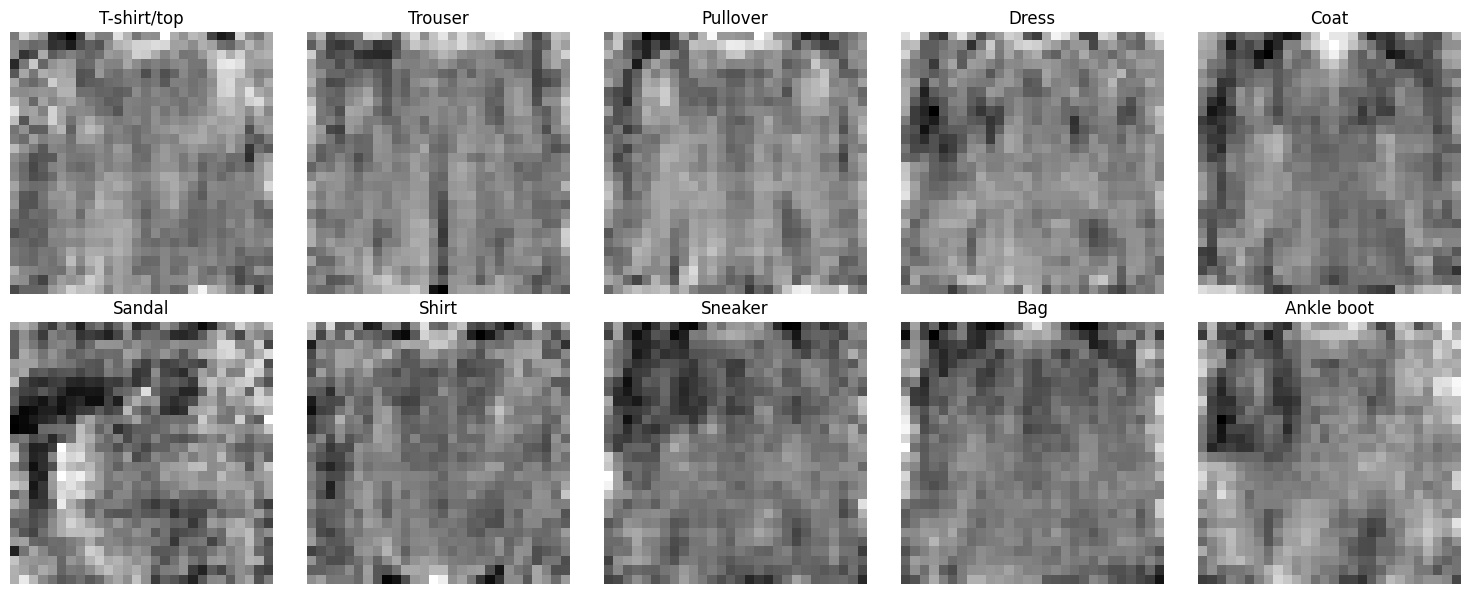

In [14]:
num_classes=len(train_data.classes)

yc=torch.eye(num_classes).to(device)

with torch.no_grad():
  z_hat=F.relu(torch.matmul(yc,W3.to(device)))
  h1_hat=F.relu(torch.matmul(z_hat,W2.to(device)))
  x_hat=torch.sigmoid(torch.matmul(h1_hat,W1.to(device)))

x_hat_img=x_hat.view(-1,28,28).cpu().numpy()

fashion_classes=train_data.classes

fig,ax=plt.subplots(2,5,figsize=(15,6))
ax=ax.flatten()

for i in range(num_classes):
  axis:Axes=ax[i]

  axis.imshow(x_hat_img[i],cmap='gray')
  axis.set_title(fashion_classes[i])
  axis.axis('off')

plt.tight_layout()
plt.show()

# Tahap 3

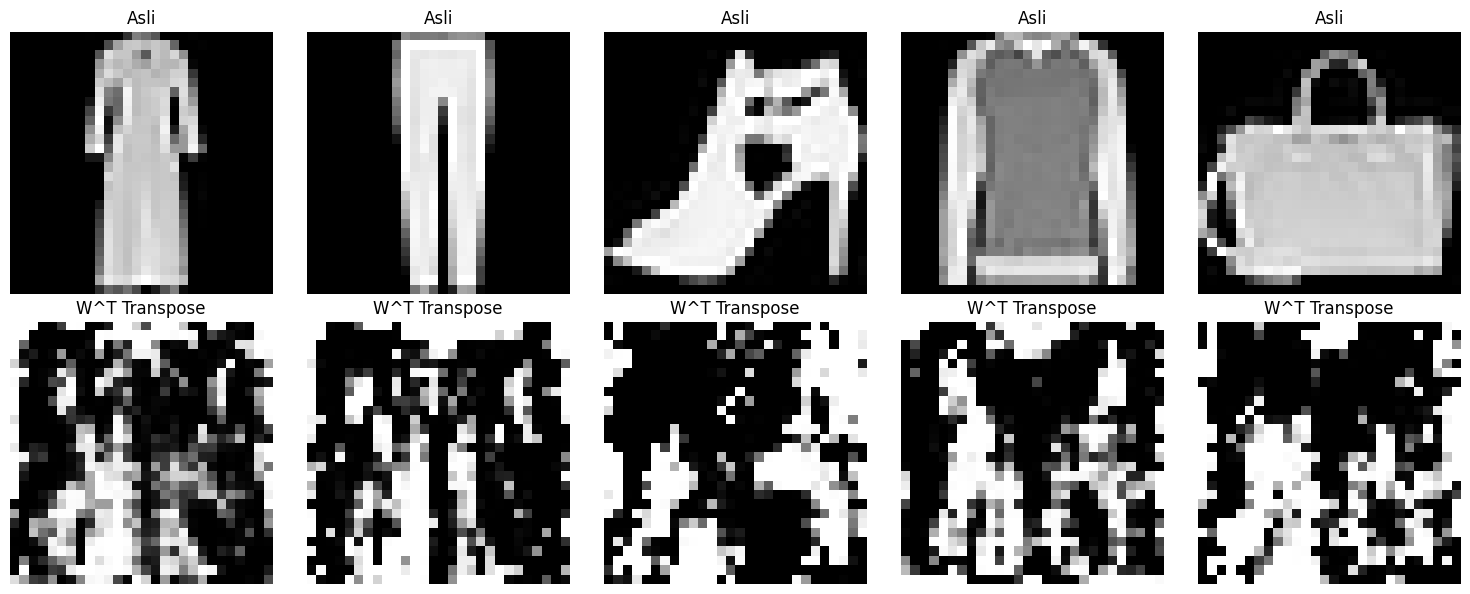

In [15]:
inputs,labels=next(iter(dataloaders['test']))
inputs=inputs.to(device)

with torch.no_grad():
  _,z_mlp,_=model(inputs)
  h1_hat=F.relu(torch.matmul(z_mlp,W2.to(device)))
  x_hat_t3=torch.sigmoid(torch.matmul(h1_hat,W1.to(device)))

fig,ax=plt.subplots(2,5,figsize=(15,6))
ax=ax.flatten()

for i in range(5):
  ax1:Axes=ax[i]
  ax1.imshow(inputs[i].cpu().view(28,28).numpy(),cmap='gray')
  ax1.axis('off')
  ax1.set_title('Asli')

  ax2:Axes=ax[i+5]
  ax2.imshow(x_hat_t3[i].cpu().view(28,28).numpy(),cmap='gray')
  ax2.axis('off')
  ax2.set_title('W^T Transpose')

plt.tight_layout()
plt.show()

# Tahap 4

In [16]:
for param in model.parameters():
  param.requires_grad=False # freeze seluruh bobot

In [17]:
class FrozenDecoder(nn.Module):
  def __init__(self):
    super().__init__()
    self.fc1=nn.Linear(64,256)
    self.fc2=nn.Linear(256,784)

  def forward(self,z):
    h=F.relu(self.fc1(z))
    x_recon=torch.sigmoid(self.fc2(h))
    return x_recon

class FrozenWrapper(nn.Module):
  def __init__(self,encoder,decoder):
    super().__init__()
    self.encoder=encoder
    self.decoder=decoder

  def forward(self,x):
    outputs=self.encoder(x)
    z_mlp=outputs[1]
    recon=self.decoder(z_mlp)
    return recon

In [18]:
decoder=FrozenDecoder().to(device)
criterion_mse=nn.MSELoss()
optimizer_dec=optim.Adam(decoder.parameters(),lr=1e-3)

In [19]:
model.eval()
history_loss_frozen=[]
start_train_frozen=time.time()
for epoch in range(EPOCHS):
  decoder.train()
  total_train_loss=0
  for batch_inputs,_ in dataloaders['train']:
    batch_inputs=batch_inputs.to(device)
    inputs_flat=batch_inputs.view(-1,784)

    with torch.no_grad():
      _,batch_z_mlp,_=model(inputs_flat)

    optimizer_dec.zero_grad()
    reconstructions=decoder(batch_z_mlp)
    loss=criterion_mse(reconstructions,inputs_flat)
    loss.backward()
    optimizer_dec.step()
    total_train_loss+=loss.item()

  decoder.eval()
  total_val_loss=0
  with torch.no_grad():
    for batch_inputs,_ in dataloaders['val']:
      batch_inputs=batch_inputs.to(device)
      inputs_flat=batch_inputs.view(-1,784)

      _,batch_z_mlp,_=model(inputs_flat)
      reconstructions=decoder(batch_z_mlp)
      loss=criterion_mse(reconstructions,inputs_flat)
      total_val_loss+=loss.item()

  avg_train = total_train_loss / len(dataloaders['train'])
  avg_val = total_val_loss / len(dataloaders['val'])
  print(f"Epoch {epoch+1}/{EPOCHS} | Train Loss: {avg_train:.4f} | Val Loss: {avg_val:.4f}")
  history_loss_frozen.append(avg_train)

time_per_epoch_frozen=(time.time()-start_train_frozen)/EPOCHS

Epoch 1/10 | Train Loss: 0.0362 | Val Loss: 0.0267
Epoch 2/10 | Train Loss: 0.0246 | Val Loss: 0.0233
Epoch 3/10 | Train Loss: 0.0223 | Val Loss: 0.0217
Epoch 4/10 | Train Loss: 0.0212 | Val Loss: 0.0208
Epoch 5/10 | Train Loss: 0.0204 | Val Loss: 0.0202
Epoch 6/10 | Train Loss: 0.0198 | Val Loss: 0.0196
Epoch 7/10 | Train Loss: 0.0193 | Val Loss: 0.0193
Epoch 8/10 | Train Loss: 0.0190 | Val Loss: 0.0189
Epoch 9/10 | Train Loss: 0.0187 | Val Loss: 0.0188
Epoch 10/10 | Train Loss: 0.0184 | Val Loss: 0.0186


In [20]:
frozen_wrapper=FrozenWrapper(model,decoder).to(device)
latency_frozen=latency(frozen_wrapper,device)
mse_frozen,psnr_frozen,ssim_frozen=calculate_metrics(frozen_wrapper,dataloaders['test'],device)
print_model_metrics("Frozen MLP",time_per_epoch_frozen,latency_frozen,mse_frozen,psnr_frozen,ssim_frozen)

--------------------------------------------------
HASIL METRIK : FROZEN MLP
--------------------------------------------------
Training Time / Epoch    : 8.13 detik
Latency (ms / batch 64)  : 0.03 ms
Test MSE                 : 0.0186
Test PSNR                : 17.31 dB
Test SSIM                : 0.6333
--------------------------------------------------


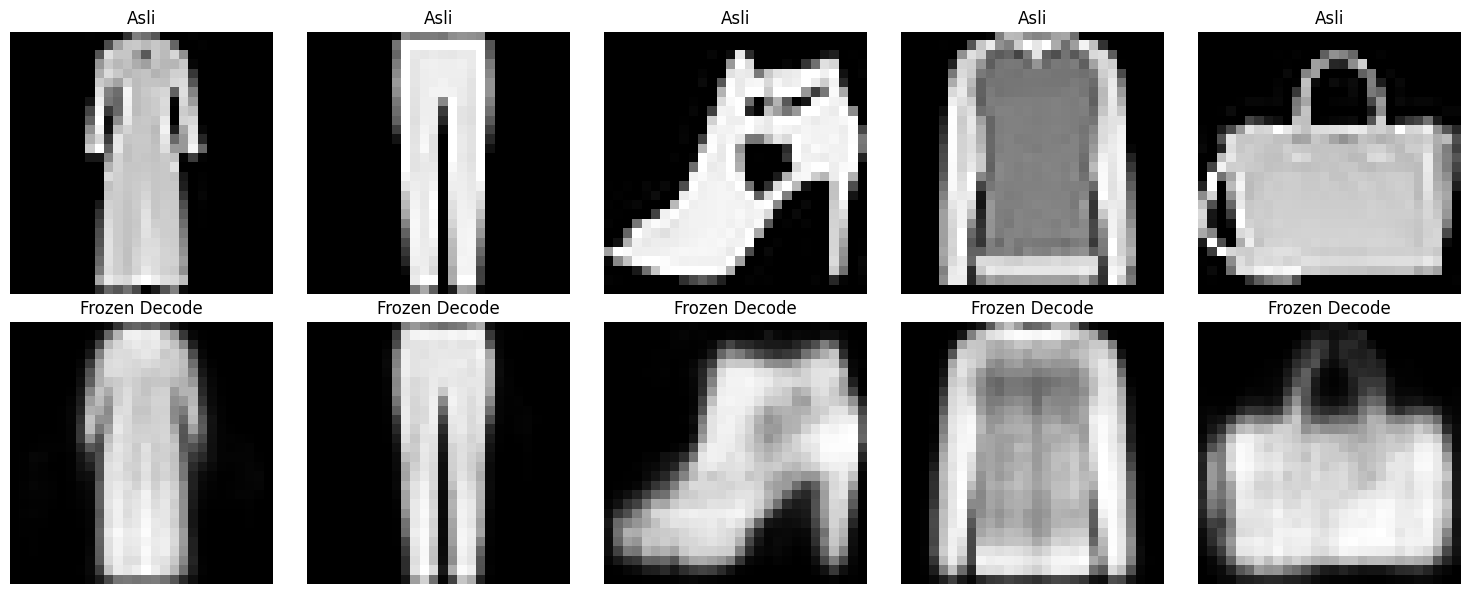

In [21]:
decoder.eval()
with torch.no_grad():
  x_hat_t4=decoder(z_mlp)

fig,ax=plt.subplots(2,5,figsize=(15,6))
ax=ax.flatten()

for i in range(5):
  ax1:Axes=ax[i]
  ax1.imshow(inputs[i].cpu().view(28,28).numpy(),cmap='gray')
  ax1.axis('off')
  ax1.set_title('Asli')

  ax2:Axes=ax[i+5]
  ax2.imshow(x_hat_t4[i].cpu().view(28,28).numpy(),cmap='gray')
  ax2.axis('off')
  ax2.set_title('Frozen Decode')

plt.tight_layout()
plt.show()

In [22]:
class Vanilla(nn.Module):
  def __init__(self):
    super().__init__()
    self.encoder=nn.Sequential(
        nn.Flatten(),
        nn.Linear(784,256),
        nn.ReLU(),
        nn.Linear(256,64),
        nn.ReLU()
    )
    self.decoder=nn.Sequential(
        nn.Linear(64,256),
        nn.ReLU(),
        nn.Linear(256,784),
        nn.Sigmoid()
    )
  def forward(self,x):
    z=self.encoder(x)
    x_recon=self.decoder(z)
    return x_recon,z

In [23]:
vanilla_ae=Vanilla().to(device)
criterion_mse=nn.MSELoss()
optimizer_vanilla=optim.Adam(vanilla_ae.parameters(),lr=1e-3)

In [24]:
history_loss_vanilla=[]
start_train_vanilla=time.time()
for epoch in range(EPOCHS):
  vanilla_ae.train()
  total_train_loss=0
  for inputs,_ in dataloaders['train']:
    inputs=inputs.to(device)
    inputs_flat=inputs.view(-1,784)
    optimizer_vanilla.zero_grad()

    reconstructions,_=vanilla_ae(inputs_flat)
    loss=criterion_mse(reconstructions,inputs_flat)
    loss.backward()
    optimizer_vanilla.step()
    total_train_loss+=loss.item()

  vanilla_ae.eval()
  total_val_loss=0
  with torch.no_grad():
    for inputs,_ in dataloaders['val']:
      inputs=inputs.to(device)
      inputs_flat=inputs.view(-1,784)
      reconstructions,_=vanilla_ae(inputs_flat)
      loss=criterion_mse(reconstructions,inputs_flat)
      total_val_loss+=loss.item()

  avg_train = total_train_loss / len(dataloaders['train'])
  avg_val = total_val_loss / len(dataloaders['val'])
  print(f"Epoch {epoch+1}/{EPOCHS} | Train Loss: {avg_train:.4f} | Val Loss: {avg_val:.4f}")

  history_loss_vanilla.append(avg_train)

time_per_epoch_vanilla=(time.time()-start_train_vanilla)/EPOCHS

Epoch 1/10 | Train Loss: 0.0349 | Val Loss: 0.0202
Epoch 2/10 | Train Loss: 0.0179 | Val Loss: 0.0163
Epoch 3/10 | Train Loss: 0.0152 | Val Loss: 0.0143
Epoch 4/10 | Train Loss: 0.0137 | Val Loss: 0.0131
Epoch 5/10 | Train Loss: 0.0126 | Val Loss: 0.0124
Epoch 6/10 | Train Loss: 0.0119 | Val Loss: 0.0116
Epoch 7/10 | Train Loss: 0.0113 | Val Loss: 0.0112
Epoch 8/10 | Train Loss: 0.0109 | Val Loss: 0.0110
Epoch 9/10 | Train Loss: 0.0105 | Val Loss: 0.0105
Epoch 10/10 | Train Loss: 0.0102 | Val Loss: 0.0102


In [25]:
latency_vanilla=latency(vanilla_ae,device)
mse_vanilla,psnr_vanilla,ssim_vanilla=calculate_metrics(vanilla_ae,dataloaders['test'],device)
print_model_metrics("Vanilla AE",time_per_epoch_vanilla,latency_vanilla,mse_vanilla,psnr_vanilla,ssim_vanilla)

--------------------------------------------------
HASIL METRIK : VANILLA AE
--------------------------------------------------
Training Time / Epoch    : 8.04 detik
Latency (ms / batch 64)  : 0.02 ms
Test MSE                 : 0.0100
Test PSNR                : 19.99 dB
Test SSIM                : 0.7509
--------------------------------------------------


# Tahap 5

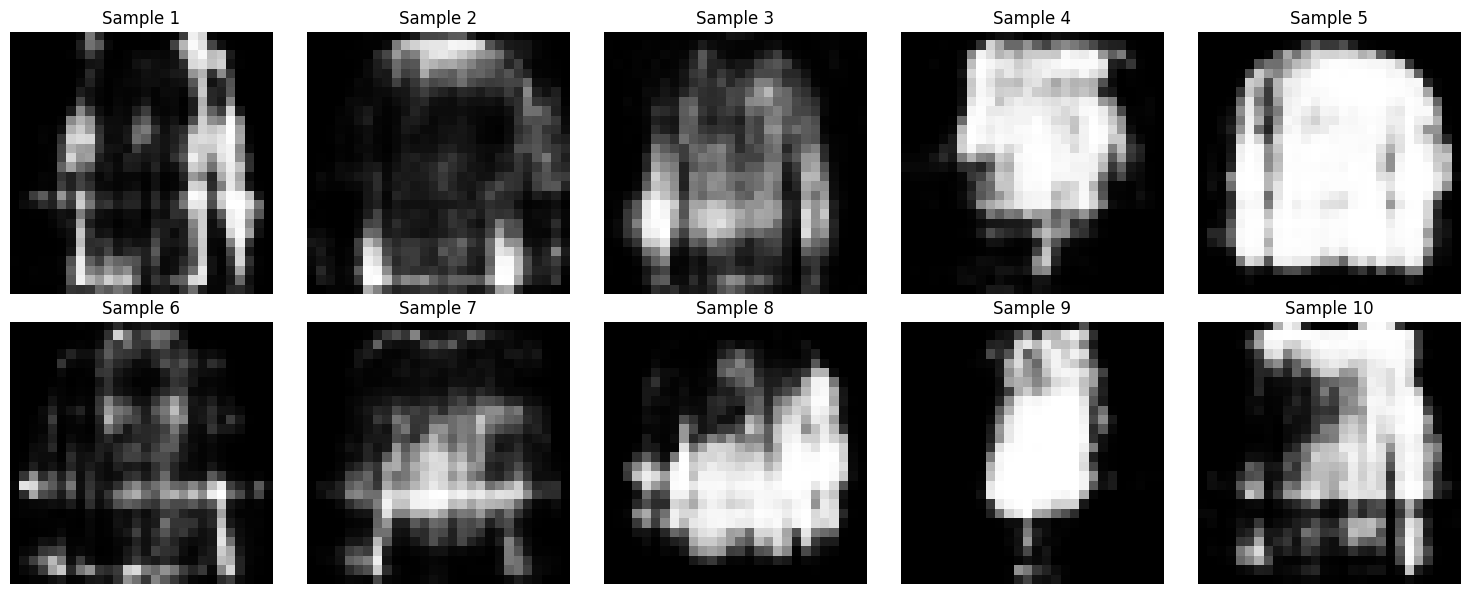

In [26]:
model.eval()
all_z_mlp=[]
with torch.no_grad():
  for inputs,_ in dataloaders['test']:
    inputs=inputs.to(device)
    _,z,_=model(inputs)
    all_z_mlp.append(z)

all_z_mlp=torch.cat(all_z_mlp,dim=0)

mu_z=torch.mean(all_z_mlp,dim=0)
std_z=torch.std(all_z_mlp,dim=0)

z_rand=torch.randn(num_samples,64).to(device)
z_rand=z_rand*std_z+mu_z

decoder.eval()
with torch.no_grad():
  generated=decoder(z_rand)

fig,ax=plt.subplots(2,int(num_samples/2),figsize=(15,6))
ax=ax.flatten()

for i in range(num_samples):
  ax1:Axes=ax[i]
  ax1.imshow(generated[i].cpu().view(28,28).numpy(),cmap='gray')
  ax1.axis('off')
  ax1.set_title(f'Sample {i+1}')

plt.tight_layout()
plt.show()

# Sparse AE

In [27]:
class Sparse(nn.Module):
  def __init__(self):
    super().__init__()
    self.encoder=nn.Sequential(
        nn.Flatten(),
        nn.Linear(784,256),
        nn.ReLU(),
        nn.Linear(256,256),
        nn.ReLU()
    )
    self.decoder=nn.Sequential(
        nn.Linear(256,256),
        nn.ReLU(),
        nn.Linear(256,784),
        nn.Sigmoid()
    )

  def forward(self,x):
    z=self.encoder(x)
    x_recon=self.decoder(z)
    return x_recon,z

In [28]:
sparse_ae=Sparse().to(device)
criterion_mse=nn.MSELoss()
optimizer_sparse=optim.Adam(sparse_ae.parameters(),lr=1e-3)

# hyperparameter untuk L1 sparsity penalty
L1=1e-4

In [29]:
history_loss_sparse=[]
start_train_sparse=time.time()
for epoch in range(EPOCHS):
  sparse_ae.train()
  total_train_loss=0
  for inputs,_ in dataloaders['train']:
    inputs=inputs.to(device)
    inputs_flat=inputs.view(-1,784)
    optimizer_sparse.zero_grad()

    reconstructions,z_sparse=sparse_ae(inputs_flat)
    mse_loss=criterion_mse(reconstructions,inputs_flat)
    l1_penalty=L1 * torch.norm(z_sparse,1)
    loss=mse_loss+l1_penalty

    loss.backward()
    optimizer_sparse.step()
    total_train_loss+=loss.item()

  sparse_ae.eval()
  total_val_loss=0
  with torch.no_grad():
    for inputs,_ in dataloaders['val']:
      inputs=inputs.to(device)
      inputs_flat=inputs.view(-1,784)
      reconstructions,z_sparse=sparse_ae(inputs_flat)
      mse_loss=criterion_mse(reconstructions,inputs_flat)
      l1_penalty=L1 * torch.norm(z_sparse,1)
      loss=mse_loss+l1_penalty
      total_val_loss+=loss.item()

  avg_train = total_train_loss / len(dataloaders['train'])
  avg_val = total_val_loss / len(dataloaders['val'])

  print(f"Epoch {epoch+1}/{EPOCHS} | Train Loss: {avg_train:.4f} | Val Loss: {avg_val:.4f}")

  history_loss_sparse.append(avg_train)

time_per_epoch_sparse=(time.time()-start_train_sparse)/EPOCHS

Epoch 1/10 | Train Loss: 0.0964 | Val Loss: 0.0872
Epoch 2/10 | Train Loss: 0.0871 | Val Loss: 0.0872
Epoch 3/10 | Train Loss: 0.0870 | Val Loss: 0.0872
Epoch 4/10 | Train Loss: 0.0870 | Val Loss: 0.0872
Epoch 5/10 | Train Loss: 0.0870 | Val Loss: 0.0872
Epoch 6/10 | Train Loss: 0.0870 | Val Loss: 0.0872
Epoch 7/10 | Train Loss: 0.0870 | Val Loss: 0.0872
Epoch 8/10 | Train Loss: 0.0870 | Val Loss: 0.0871
Epoch 9/10 | Train Loss: 0.0870 | Val Loss: 0.0872
Epoch 10/10 | Train Loss: 0.0870 | Val Loss: 0.0872


In [30]:
latency_sparse=latency(sparse_ae,device)
mse_sparse,psnr_sparse,ssim_sparse=calculate_metrics(sparse_ae,dataloaders['test'],device)
print_model_metrics("Sparse AE",time_per_epoch_sparse,latency_sparse,mse_sparse,psnr_sparse,ssim_sparse)

--------------------------------------------------
HASIL METRIK : SPARSE AE
--------------------------------------------------
Training Time / Epoch    : 8.51 detik
Latency (ms / batch 64)  : 0.02 ms
Test MSE                 : 0.0868
Test PSNR                : 10.62 dB
Test SSIM                : 0.1718
--------------------------------------------------


# VAE

In [31]:
class VAE(nn.Module):
  def __init__(self,latent_dim=LATENT_DIM):
    super().__init__()
    self.encoder=nn.Sequential(
        nn.Flatten(),
        nn.Linear(784,256),
        nn.ReLU(),
    )
    self.fc_mu=nn.Linear(256,latent_dim)
    self.fc_logvar=nn.Linear(256,latent_dim)

    self.decoder=nn.Sequential(
        nn.Linear(latent_dim,256),
        nn.ReLU(),
        nn.Linear(256,784),
        nn.Sigmoid()
    )

  def encode(self,x):
    h=self.encoder(x)
    return self.fc_mu(h),self.fc_logvar(h)

  def reparameterize(self,mu,logvar):
    std=torch.exp(0.5*logvar)
    eps=torch.randn_like(std)
    return mu+eps*std

  def forward(self,x):
    mu,logvar=self.encode(x)
    z=self.reparameterize(mu,logvar)
    recon=self.decoder(z)
    return recon,mu,logvar,z

def vae_loss_function(recon_x,x,mu,logvar):
  BCE=nn.BCELoss(reduction='sum')(recon_x,x.view(-1,784))
  KLD=-0.5*torch.sum(1+logvar-mu.pow(2)-logvar.exp())
  return BCE+KLD

In [32]:
vae=VAE().to(device)
optimizer_vae=optim.Adam(vae.parameters(),lr=1e-3)

In [33]:
history_loss_vae=[]
start_train_vae=time.time()
for epoch in range(EPOCHS):
  vae.train()
  total_train_loss=0
  for inputs,_ in dataloaders['train']:
    inputs=inputs.to(device)
    inputs_flat=inputs.view(-1,784)
    optimizer_vae.zero_grad()

    reconstructions,mu,logvar,_=vae(inputs_flat)
    loss=vae_loss_function(reconstructions,inputs_flat,mu,logvar)

    loss.backward()
    optimizer_vae.step()
    total_train_loss+=loss.item()

  vae.eval()
  total_val_loss=0
  with torch.no_grad():
    for inputs,_ in dataloaders['val']:
      inputs=inputs.to(device)
      inputs_flat=inputs.view(-1,784)
      reconstructions,mu,logvar,_=vae(inputs_flat)
      loss=vae_loss_function(reconstructions,inputs_flat,mu,logvar)
      total_val_loss+=loss.item()

  avg_train = total_train_loss / len(dataloaders['train'])
  avg_val = total_val_loss / len(dataloaders['val'])

  print(f"Epoch {epoch+1}/{EPOCHS} | Train Loss: {avg_train:.4f} | Val Loss: {avg_val:.4f}")

  history_loss_vae.append(avg_train)

time_per_epoch_vae=(time.time()-start_train_vae)/EPOCHS

Epoch 1/10 | Train Loss: 38428.3903 | Val Loss: 34896.6822
Epoch 2/10 | Train Loss: 34252.1880 | Val Loss: 33587.0945
Epoch 3/10 | Train Loss: 33130.2077 | Val Loss: 32713.5197
Epoch 4/10 | Train Loss: 32461.1430 | Val Loss: 32164.0273
Epoch 5/10 | Train Loss: 32011.2720 | Val Loss: 31948.3197
Epoch 6/10 | Train Loss: 31750.8180 | Val Loss: 31634.8488
Epoch 7/10 | Train Loss: 31572.2454 | Val Loss: 31533.3364
Epoch 8/10 | Train Loss: 31450.9151 | Val Loss: 31350.2380
Epoch 9/10 | Train Loss: 31349.5706 | Val Loss: 31322.8668
Epoch 10/10 | Train Loss: 31272.9937 | Val Loss: 31205.5213


In [34]:
latency_vae=latency(vae,device)
mse_vae,psnr_vae,ssim_vae=calculate_metrics(vae,dataloaders['test'],device)
print_model_metrics("VAE",time_per_epoch_vae,latency_vae,mse_vae,psnr_vae,ssim_vae)

--------------------------------------------------
HASIL METRIK : VAE
--------------------------------------------------
Training Time / Epoch    : 8.57 detik
Latency (ms / batch 64)  : 0.03 ms
Test MSE                 : 0.0171
Test PSNR                : 17.68 dB
Test SSIM                : 0.6568
--------------------------------------------------


# GAN

In [35]:
class Generator(nn.Module):
  def __init__(self):
    super().__init__()
    self.model=nn.Sequential(
        nn.Linear(LATENT_DIM,256),
        nn.ReLU(True),
        nn.Linear(256,512),
        nn.ReLU(True),
        nn.Linear(512,784),
        nn.Sigmoid()
    )

  def forward(self,z):
    return self.model(z).view(-1,1,28,28)

class Discriminator(nn.Module):
  def __init__(self):
    super().__init__()
    self.model=nn.Sequential(
        nn.Flatten(),
        nn.Linear(784,512),
        nn.LeakyReLU(0.2,inplace=True),
        nn.Linear(512,256),
        nn.LeakyReLU(0.2,inplace=True),
        nn.Linear(256,1),
        nn.Sigmoid()
    )

  def forward(self,x):
    return self.model(x)

In [36]:
generator=Generator().to(device)
discriminator=Discriminator().to(device)

criterion_gan=nn.BCELoss()
optimizer_G=optim.Adam(generator.parameters(),lr=2e-4,betas=(0.5,0.999))
optimizer_D=optim.Adam(discriminator.parameters(),lr=2e-4,betas=(0.5,0.999))

In [37]:
history_loss_gan_d=[]
history_loss_gan_g=[]
start_train_gan=time.time()
for epoch in range(EPOCHS):
  generator.train()
  discriminator.train()

  total_train_d_loss,total_train_g_loss=0,0

  for i,(real_imgs,_) in enumerate(dataloaders['train']):
    real_imgs=real_imgs.to(device)
    batch_size=real_imgs.size(0)

    valid_labels=torch.ones(batch_size,1).to(device)
    fake_labels=torch.zeros(batch_size,1).to(device)

    # train discriminator
    optimizer_D.zero_grad()

    real_preds=discriminator(real_imgs)
    d_real_loss=criterion_gan(real_preds,valid_labels)

    z=torch.randn(batch_size,LATENT_DIM).to(device)
    fake_imgs=generator(z)
    fake_preds=discriminator(fake_imgs.detach())
    d_fake_loss=criterion_gan(fake_preds,fake_labels)

    d_loss=(d_real_loss+d_fake_loss)/2
    d_loss.backward()
    optimizer_D.step()
    total_train_d_loss+=d_loss.item()

    # train generator
    optimizer_G.zero_grad()

    fake_preds=discriminator(fake_imgs)
    g_loss=criterion_gan(fake_preds,valid_labels)

    g_loss.backward()
    optimizer_G.step()
    total_train_g_loss+=g_loss.item()

  generator.eval()
  discriminator.eval()
  total_val_d_loss,total_val_g_loss=0,0

  with torch.no_grad():
    for inputs, _ in dataloaders['val']:
        inputs = inputs.to(device)
        batch_size = inputs.size(0)
        valid_labels = torch.ones(batch_size, 1).to(device)
        fake_labels = torch.zeros(batch_size, 1).to(device)

        real_pred = discriminator(inputs)
        d_real_loss = criterion_gan(real_pred, valid_labels)
        z = torch.randn(batch_size, LATENT_DIM).to(device)
        fake_imgs = generator(z)
        fake_pred = discriminator(fake_imgs)
        d_fake_loss = criterion_gan(fake_pred, fake_labels)

        total_val_d_loss += ((d_real_loss + d_fake_loss) / 2).item()

        fake_pred_for_G = discriminator(fake_imgs)
        total_val_g_loss += criterion_gan(fake_pred_for_G,valid_labels).item()

  avg_train_d = total_train_d_loss / len(dataloaders['train'])
  avg_train_g = total_train_g_loss / len(dataloaders['train'])
  avg_val_d = total_val_d_loss / len(dataloaders['val'])
  avg_val_g = total_val_g_loss / len(dataloaders['val'])

  print(f"Epoch {epoch+1}/{EPOCHS} | Train D: {avg_train_d:.4f}, G: {avg_train_g:.4f} | Val D: {avg_val_d:.4f}, G: {avg_val_g:.4f}")
  history_loss_gan_d.append(avg_train_d)
  history_loss_gan_g.append(avg_train_g)

time_per_epoch_gan=(time.time()-start_train_gan)/EPOCHS

Epoch 1/10 | Train D: 0.2564, G: 2.6006 | Val D: 0.2531, G: 2.7673
Epoch 2/10 | Train D: 0.2657, G: 2.9105 | Val D: 0.3493, G: 2.4034
Epoch 3/10 | Train D: 0.2640, G: 2.5735 | Val D: 0.2200, G: 2.7185
Epoch 4/10 | Train D: 0.3172, G: 2.5429 | Val D: 0.3181, G: 1.2994
Epoch 5/10 | Train D: 0.3066, G: 2.2993 | Val D: 0.3273, G: 1.0590
Epoch 6/10 | Train D: 0.3595, G: 2.0205 | Val D: 0.3917, G: 0.9799
Epoch 7/10 | Train D: 0.3654, G: 2.0067 | Val D: 0.3246, G: 1.3535
Epoch 8/10 | Train D: 0.3479, G: 2.2111 | Val D: 0.3676, G: 0.9324
Epoch 9/10 | Train D: 0.3816, G: 1.9960 | Val D: 0.3401, G: 1.5455
Epoch 10/10 | Train D: 0.3837, G: 1.9090 | Val D: 0.2982, G: 1.5490


In [38]:
latency_gan=latency(generator,device,input_shape=(LATENT_DIM,))
print_model_metrics("GAN",time_per_epoch_gan,latency_gan,None,None,None)

--------------------------------------------------
HASIL METRIK : GAN
--------------------------------------------------
Training Time / Epoch    : 9.63 detik
Latency (ms / batch 64)  : 0.01 ms
Test MSE, PSNR, SSIM     : N/A (Model Sintesis Murni)
--------------------------------------------------


# DCGAN

In [39]:
class DCGenerator(nn.Module):
  def __init__(self):
    super().__init__()
    self.main=nn.Sequential(
        nn.ConvTranspose2d(LATENT_DIM,128,7,1,0,bias=False),
        nn.BatchNorm2d(128),
        nn.ReLU(True),
        nn.ConvTranspose2d(128,64,4,2,1,bias=False),
        nn.BatchNorm2d(64),
        nn.ReLU(True),
        nn.ConvTranspose2d(64,1,4,2,1,bias=False),
        nn.Sigmoid()
    )

  def forward(self,z):
    return self.main(z)

class DCDiscriminator(nn.Module):
  def __init__(self):
    super().__init__()
    self.main=nn.Sequential(
        nn.Conv2d(1,64,4,2,1,bias=False),
        nn.LeakyReLU(0.2,inplace=True),
        nn.Conv2d(64,128,4,2,1,bias=False),
        nn.BatchNorm2d(128),
        nn.LeakyReLU(0.2,inplace=True),
        nn.Flatten(),
        nn.Linear(128*7*7,1),
        nn.Sigmoid()
    )

  def forward(self,x):
    return self.main(x)

In [40]:
generator_dc=DCGenerator().to(device)
discriminator_dc=DCDiscriminator().to(device)

criterion_gan=nn.BCELoss()
optimizer_G_dc=optim.Adam(generator_dc.parameters(),lr=2e-4,betas=(0.5,0.999))
optimizer_D_dc=optim.Adam(discriminator_dc.parameters(),lr=2e-4,betas=(0.5,0.999))

In [41]:
history_loss_dcgan_d=[]
history_loss_dcgan_g=[]
start_train_dcgan=time.time()
for epoch in range(EPOCHS):
  generator_dc.train()
  discriminator_dc.train()

  total_train_g_loss,total_train_d_loss=0,0

  for i,(real_imgs,_) in enumerate(dataloaders['train']):
    real_imgs=real_imgs.to(device)
    batch_size=real_imgs.size(0)

    valid_labels=torch.ones(batch_size,1).to(device)
    fake_labels=torch.zeros(batch_size,1).to(device)

    # train discriminator
    optimizer_D_dc.zero_grad()

    real_preds=discriminator_dc(real_imgs)
    d_real_loss=criterion_gan(real_preds,valid_labels)

    z=torch.randn(batch_size,LATENT_DIM,1,1).to(device)
    fake_imgs=generator_dc(z)

    fake_preds=discriminator_dc(fake_imgs.detach())
    d_fake_loss=criterion_gan(fake_preds,fake_labels)

    d_loss=(d_real_loss+d_fake_loss)/2
    d_loss.backward()
    optimizer_D_dc.step()
    total_train_d_loss+=d_loss.item()

    # train generator
    optimizer_G_dc.zero_grad()

    fake_preds=discriminator_dc(fake_imgs)
    g_loss=criterion_gan(fake_preds,valid_labels)

    g_loss.backward()
    optimizer_G_dc.step()
    total_train_g_loss+=g_loss.item()

  generator_dc.eval()
  discriminator_dc.eval()
  total_val_d_loss = 0
  total_val_g_loss = 0

  with torch.no_grad():
      for inputs, _ in dataloaders['val']:
          inputs = inputs.to(device)
          batch_size = inputs.size(0)

          valid_labels = torch.ones(batch_size, 1).to(device)
          fake_labels = torch.zeros(batch_size, 1).to(device)

          real_pred = discriminator_dc(inputs)
          d_real_loss = criterion_gan(real_pred, valid_labels)

          z = torch.randn(batch_size, LATENT_DIM, 1, 1).to(device)
          fake_imgs = generator_dc(z)
          fake_pred = discriminator_dc(fake_imgs)
          d_fake_loss = criterion_gan(fake_pred, fake_labels)

          val_d_loss = (d_real_loss + d_fake_loss) / 2
          total_val_d_loss += val_d_loss.item()


          fake_pred_for_G = discriminator_dc(fake_imgs)
          val_g_loss = criterion_gan(fake_pred_for_G, valid_labels)
          total_val_g_loss += val_g_loss.item()

  avg_train_d = total_train_d_loss / len(dataloaders['train'])
  avg_train_g = total_train_g_loss / len(dataloaders['train'])
  avg_val_d = total_val_d_loss / len(dataloaders['val'])
  avg_val_g = total_val_g_loss / len(dataloaders['val'])

  print(f"Epoch {epoch+1}/{EPOCHS} | Train D: {avg_train_d:.4f}, G: {avg_train_g:.4f} | Val D: {avg_val_d:.4f}, G: {avg_val_g:.4f}")

  history_loss_dcgan_d.append(avg_train_d)
  history_loss_dcgan_g.append(avg_train_g)

time_per_epoch_dcgan = (time.time() - start_train_dcgan) / EPOCHS

Epoch 1/10 | Train D: 0.4516, G: 1.3123 | Val D: 0.6427, G: 1.5917
Epoch 2/10 | Train D: 0.5146, G: 1.1075 | Val D: 0.5665, G: 1.0105
Epoch 3/10 | Train D: 0.5481, G: 1.0642 | Val D: 0.5704, G: 1.0697
Epoch 4/10 | Train D: 0.5685, G: 1.0282 | Val D: 0.6182, G: 0.7225
Epoch 5/10 | Train D: 0.5804, G: 1.0105 | Val D: 0.6195, G: 1.0768
Epoch 6/10 | Train D: 0.5875, G: 1.0082 | Val D: 0.6281, G: 1.0876
Epoch 7/10 | Train D: 0.5935, G: 1.0049 | Val D: 0.5988, G: 0.7737
Epoch 8/10 | Train D: 0.5939, G: 1.0013 | Val D: 0.6291, G: 0.7135
Epoch 9/10 | Train D: 0.5949, G: 1.0019 | Val D: 0.6605, G: 0.9448
Epoch 10/10 | Train D: 0.5959, G: 1.0006 | Val D: 0.6197, G: 0.8650


In [42]:
latency_dcgan=latency(generator_dc,device,input_shape=(LATENT_DIM,1,1))
print_model_metrics("DCGAN",time_per_epoch_dcgan,latency_dcgan,None,None,None)

--------------------------------------------------
HASIL METRIK : DCGAN
--------------------------------------------------
Training Time / Epoch    : 11.18 detik
Latency (ms / batch 64)  : 0.04 ms
Test MSE, PSNR, SSIM     : N/A (Model Sintesis Murni)
--------------------------------------------------


# DPPM

In [43]:
# konfigurasi forward diffusion
T=100
beta=torch.linspace(1e-4,0.02,T).to(device)
alpha=1.0-beta
alpha_bar=torch.cumprod(alpha,dim=0)

In [44]:
class LightUNet(nn.Module):
  def __init__(self):
    super().__init__()
    self.time_emb=nn.Sequential(
        nn.Linear(1,64),
        nn.ReLU(),
        nn.Linear(64,64)
    )
    self.encoder=nn.Sequential(
        nn.Conv2d(1,64,3,padding=1),
        nn.ReLU(),
        nn.Conv2d(64,64,3,2,1),
        nn.ReLU()
    )
    self.time_proj=nn.Linear(64,64)
    self.decoder=nn.Sequential(
        nn.ConvTranspose2d(64,64,4,2,1),
        nn.ReLU(),
        nn.Conv2d(64,1,3,padding=1),
    )

  def forward(self,x,t):
    t_val=t.float().unsqueeze(1)
    t_emb=self.time_emb(t_val)

    x_enc=self.encoder(x)

    t_emb_spatial=self.time_proj(t_emb).unsqueeze(2).unsqueeze(3)
    x_enc=x_enc+t_emb_spatial

    out=self.decoder(x_enc)
    return out

In [45]:
unet=LightUNet().to(device)
optimizer_ddpm=optim.Adam(unet.parameters(),lr=1e-3)
criterion_ddpm=nn.MSELoss()

In [46]:
history_loss_ddpm=[]
start_train_ddpm=time.time()
for epoch in range(EPOCHS):
  unet.train()
  total_train_loss=0
  for inputs,_ in dataloaders['train']:
    inputs=inputs.to(device)
    batch_size=inputs.size(0)

    t=torch.randint(0,T,(batch_size,),device=device).long()
    noise=torch.randn_like(inputs).to(device)

    # rumus forward diffusion
    a_bar_t=alpha_bar[t].view(-1,1,1,1)
    x_t=torch.sqrt(a_bar_t)*inputs+torch.sqrt(1-a_bar_t)*noise

    optimizer_ddpm.zero_grad()
    pred_noise=unet(x_t,t)

    loss=criterion_ddpm(pred_noise,noise)
    loss.backward()
    optimizer_ddpm.step()
    total_train_loss+=loss.item()

  unet.eval()
  total_val_loss = 0
  with torch.no_grad():
      for inputs, _ in dataloaders['val']:
          inputs = inputs.to(device)
          batch_size = inputs.size(0)

          t = torch.randint(0, T, (batch_size,), device=device).long()
          noise = torch.randn_like(inputs).to(device)
          a_bar_t = alpha_bar[t].view(-1, 1, 1, 1)
          x_t = torch.sqrt(a_bar_t) * inputs + torch.sqrt(1 - a_bar_t) * noise

          predicted_noise = unet(x_t, t)
          loss = criterion_ddpm(predicted_noise, noise)
          total_val_loss += loss.item()

  avg_train = total_train_loss / len(dataloaders['train'])
  avg_val = total_val_loss / len(dataloaders['val'])

  print(f"Epoch {epoch+1}/{EPOCHS} | Train MSE: {avg_train:.4f} | Val MSE: {avg_val:.4f}")
  history_loss_ddpm.append(avg_train)

time_per_epoch_ddpm = (time.time() - start_train_ddpm) / EPOCHS

Epoch 1/10 | Train MSE: 0.3017 | Val MSE: 0.1545
Epoch 2/10 | Train MSE: 0.1440 | Val MSE: 0.1354
Epoch 3/10 | Train MSE: 0.1286 | Val MSE: 0.1219
Epoch 4/10 | Train MSE: 0.1208 | Val MSE: 0.1183
Epoch 5/10 | Train MSE: 0.1162 | Val MSE: 0.1144
Epoch 6/10 | Train MSE: 0.1116 | Val MSE: 0.1115
Epoch 7/10 | Train MSE: 0.1089 | Val MSE: 0.1080
Epoch 8/10 | Train MSE: 0.1076 | Val MSE: 0.1073
Epoch 9/10 | Train MSE: 0.1059 | Val MSE: 0.1048
Epoch 10/10 | Train MSE: 0.1034 | Val MSE: 0.1023


In [47]:
unet.eval()
dummy_noise=torch.randn(64,1,28,28).to(device)

# warm up
with torch.no_grad():
  x_warm=dummy_noise.clone()
  for t_step in reversed(range(T)):
    t_tensor=torch.full((64,),t_step,device=device,dtype=torch.long)
    _=unet(x_warm,t_tensor)

start_latency=time.time()
with torch.no_grad():
  x_lat=dummy_noise.clone()
  for t_step in reversed(range(T)):
    t_tensor=torch.full((64,),t_step,device=device,dtype=torch.long)
    x_lat=unet(x_lat,t_tensor)
    x_lat-=pred_noise
end_latency=time.time()

latency_ddpm=(end_latency-start_latency)*1000
print_model_metrics("DDPM (T=100)",time_per_epoch_ddpm,latency_ddpm,None,None,None)

--------------------------------------------------
HASIL METRIK : DDPM (T=100)
--------------------------------------------------
Training Time / Epoch    : 9.55 detik
Latency (ms / batch 64)  : 262.20 ms
Test MSE, PSNR, SSIM     : N/A (Model Sintesis Murni)
--------------------------------------------------


# Figur 1: Grid Rekonstruksi Side-by-Side:

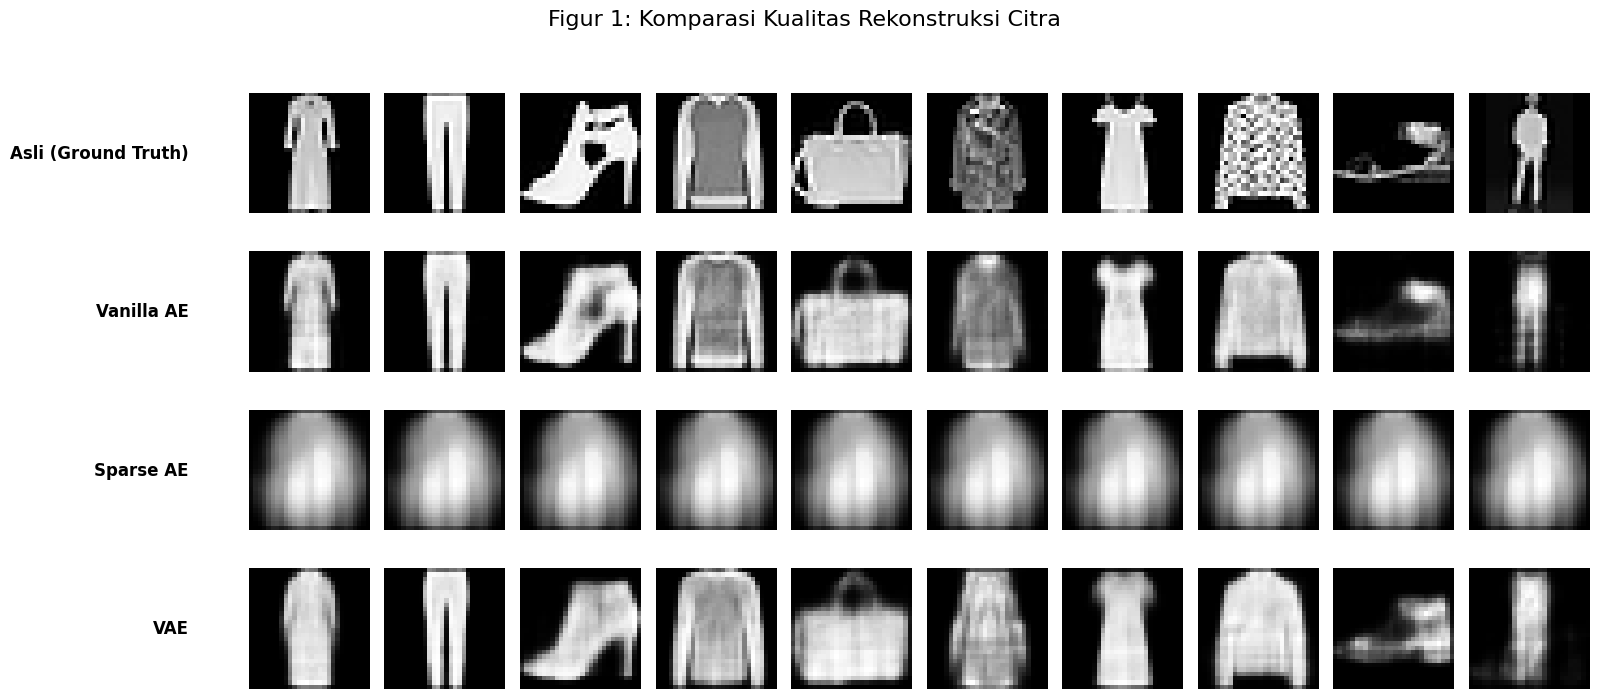

In [48]:
inputs,_=next(iter(dataloaders['test']))
inputs=inputs[:10].to(device)

vanilla_ae.eval()
sparse_ae.eval()
vae.eval()

with torch.no_grad():
  recon_vanilla,_=vanilla_ae(inputs)
  recon_sparse,_=sparse_ae(inputs)
  recon_vae,_,_,_=vae(inputs)

imgs_asli=inputs.cpu().squeeze().numpy()
imgs_vanilla=recon_vanilla.view(-1,28,28).cpu().squeeze().numpy()
imgs_sparse=recon_sparse.view(-1,28,28).cpu().squeeze().numpy()
imgs_vae=recon_vae.view(-1,28,28).cpu().squeeze().numpy()

fig, axes = plt.subplots(4, 10, figsize=(16, 7))
kumpulan_data = [imgs_asli, imgs_vanilla, imgs_sparse, imgs_vae]
label_baris = ['Asli (Ground Truth)', 'Vanilla AE', 'Sparse AE', 'VAE']

for i in range(4):
    for j in range(10):
        ax = axes[i, j]
        ax.imshow(kumpulan_data[i][j], cmap='gray')
        ax.axis('off')

        if j == 0:
            ax.text(-0.5, 0.5, label_baris[i], va='center', ha='right',
                    transform=ax.transAxes, fontsize=12, fontweight='bold')

plt.subplots_adjust(left=0.15)
plt.suptitle("Figur 1: Komparasi Kualitas Rekonstruksi Citra", fontsize=16, y=1.02)
plt.tight_layout()

plt.savefig('figur_1.png', dpi=300, bbox_inches='tight')
plt.show()

#  Figur 2: Grid Random Generative Sampling

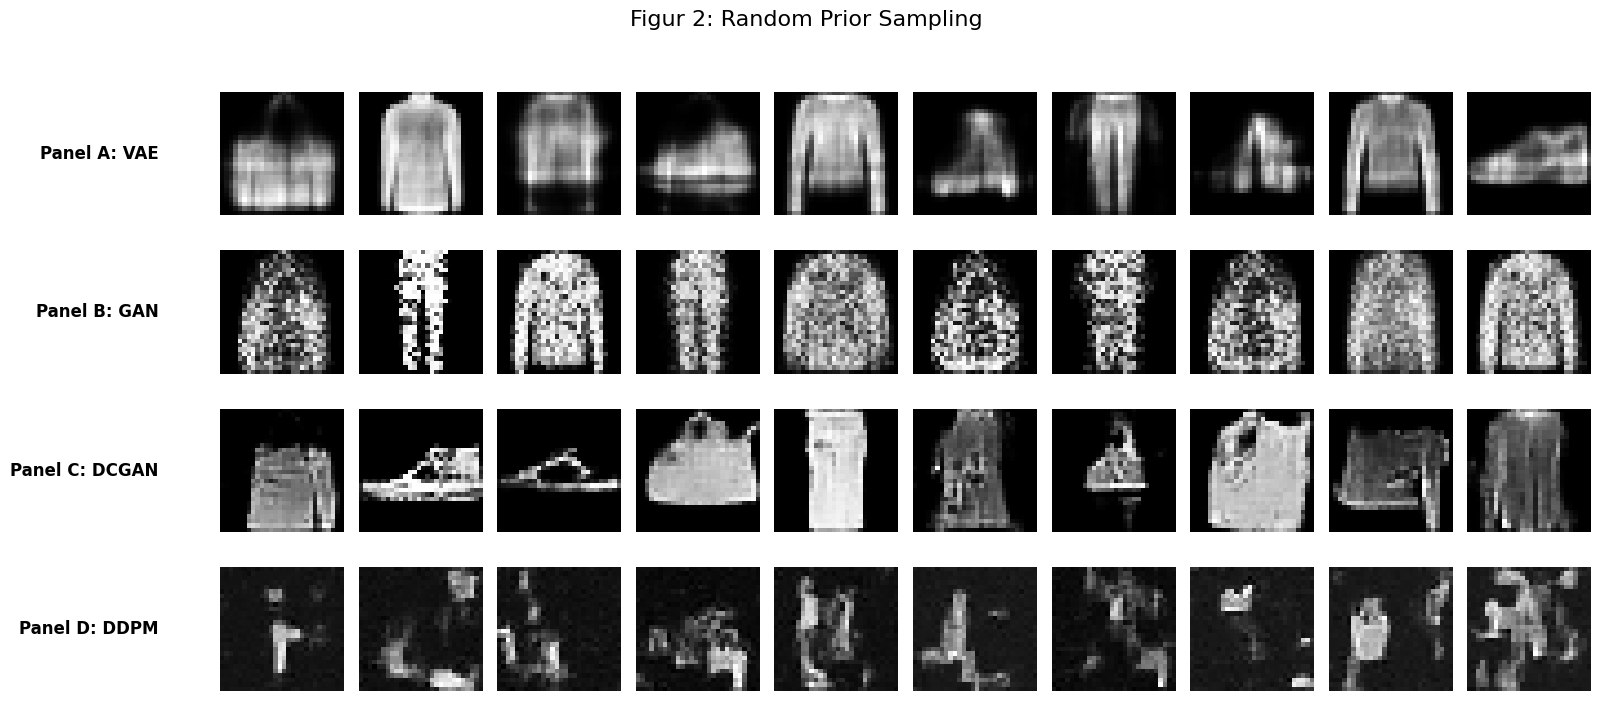

In [49]:
vae.eval()
generator.eval()
generator_dc.eval()
unet.eval()

with torch.no_grad():
  # panel A
  z_vae=torch.randn(num_samples,64).to(device)
  samples_vae=vae.decoder(z_vae).view(-1,28,28).cpu().numpy()

  # panel B
  z_gan=torch.randn(num_samples,64).to(device)
  samples_gan=generator(z_gan).view(-1,28,28).cpu().numpy()

  # panel C
  z_dcgan=torch.randn(num_samples,LATENT_DIM,1,1).to(device)
  samples_dcgan=generator_dc(z_dcgan).view(-1,28,28).cpu().numpy()

  # panel D
  x_ddpm=torch.randn(num_samples,1,28,28).to(device)
  for t_step in reversed(range(T)):
    t_tensor=torch.full((num_samples,),t_step,device=device,dtype=torch.long)
    pred_noise=unet(x_ddpm,t_tensor)

    beta_t=beta[t_step]
    alpha_t=alpha[t_step]
    a_bar_t=alpha_bar[t_step]

    noise=torch.randn_like(x_ddpm) if t_step>0 else torch.zeros_like(x_ddpm)
    x_ddpm=(1/torch.sqrt(alpha_t))*(x_ddpm-((1-alpha_t)/torch.sqrt(1-a_bar_t))*pred_noise)+torch.sqrt(beta_t)*noise

  samples_ddpm=x_ddpm.view(-1,28,28).cpu().numpy()

kumpulan_samples = [samples_vae, samples_gan, samples_dcgan, samples_ddpm]
label_baris = ['Panel A: VAE', 'Panel B: GAN', 'Panel C: DCGAN', 'Panel D: DDPM']

fig, axes = plt.subplots(4, 10, figsize=(16, 7))

for i in range(4):
    for j in range(10):
        ax = axes[i, j]
        img = kumpulan_samples[i][j]

        if i == 3:
            img = (img - img.min()) / (img.max() - img.min() + 1e-8)

        ax.imshow(img, cmap='gray')
        ax.axis('off')

        if j == 0:
            ax.text(-0.5, 0.5, label_baris[i], va='center', ha='right',
                    transform=ax.transAxes, fontsize=12, fontweight='bold')

plt.subplots_adjust(left=0.15)
plt.suptitle("Figur 2: Random Prior Sampling", fontsize=16, y=1.02)
plt.tight_layout()

plt.savefig('figur_2.png', dpi=300, bbox_inches='tight')
plt.show()

# Figur 3: Bukti Empiris Batasan Bobot dan Latent Features MLP Classifier

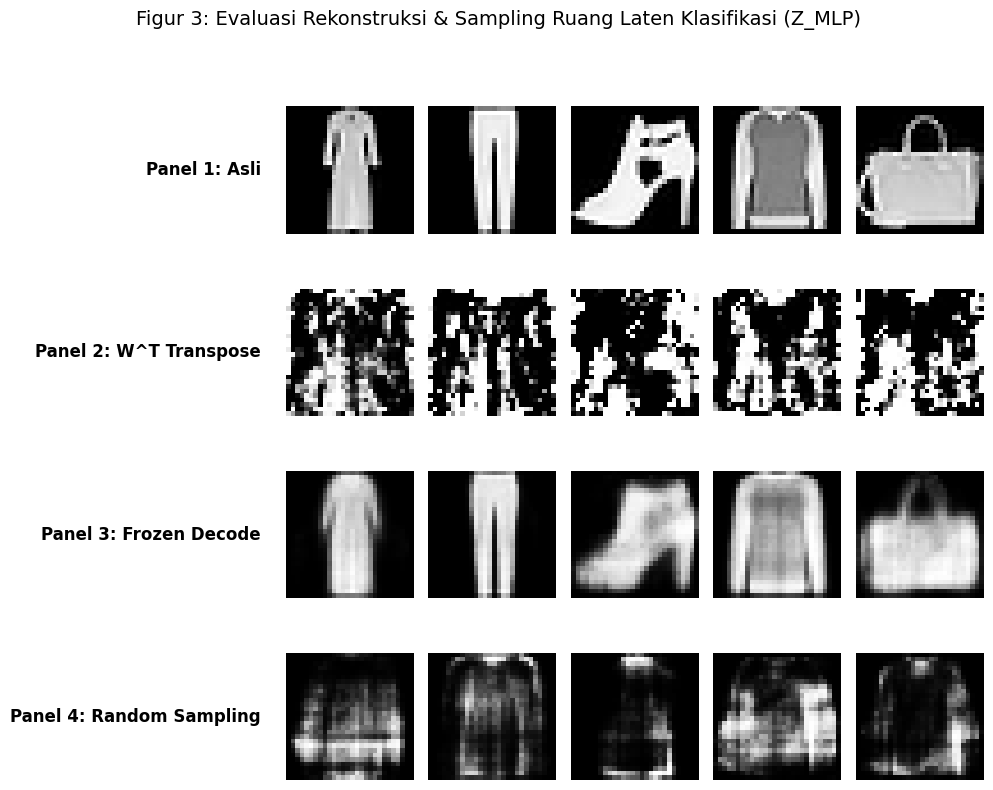

In [50]:
inputs,_=next(iter(dataloaders['test']))
inputs=inputs[:5].to(device)

model.eval()
decoder.eval()

with torch.no_grad():
  # panel 1
  _,z_mlp,_=model(inputs)

  # panel 2
  h1_hat=F.relu(torch.matmul(z_mlp,W2.to(device)))
  x_hat_transpose=torch.sigmoid(torch.matmul(h1_hat,W1.to(device)))

  # panel 3
  x_hat_frozen=decoder(z_mlp)

  # panel 4
  z_rand=torch.randn(5,64).to(device)*std_z+mu_z
  x_hat_random=decoder(z_rand)

imgs_asli = inputs.cpu().squeeze().numpy()
imgs_transpose = x_hat_transpose.view(-1, 28, 28).cpu().numpy()
imgs_frozen = x_hat_frozen.view(-1, 28, 28).cpu().numpy()
imgs_random = x_hat_random.view(-1, 28, 28).cpu().numpy()

kumpulan_data = [imgs_asli, imgs_transpose, imgs_frozen, imgs_random]
label_baris = ['Panel 1: Asli', 'Panel 2: W^T Transpose', 'Panel 3: Frozen Decode', 'Panel 4: Random Sampling']

fig, axes = plt.subplots(4, 5, figsize=(10, 8))

for i in range(4):
    for j in range(5):
        ax = axes[i, j]
        ax.imshow(kumpulan_data[i][j], cmap='gray')
        ax.axis('off')

        if j == 0:
            ax.text(-0.2, 0.5, label_baris[i], va='center', ha='right',
                    transform=ax.transAxes, fontsize=12, fontweight='bold')

plt.subplots_adjust(left=0.25)
plt.suptitle("Figur 3: Evaluasi Rekonstruksi & Sampling Ruang Laten Klasifikasi (Z_MLP)", fontsize=14, y=1.02)
plt.tight_layout()

# Simpan otomatis
plt.savefig('figur3.png', dpi=300, bbox_inches='tight')
plt.show()

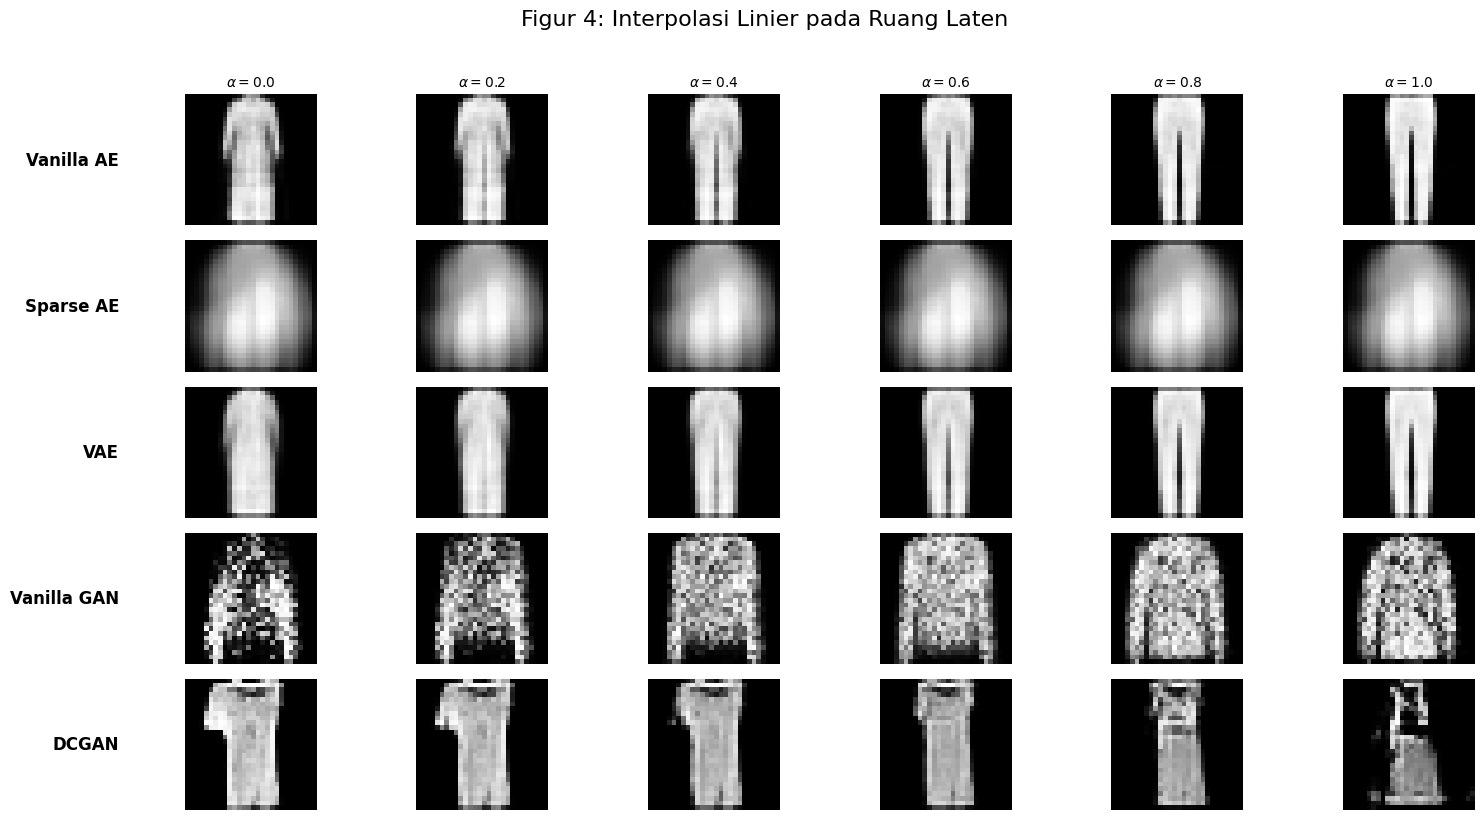

In [51]:
alphas=torch.tensor([0.0,0.2,0.4,0.6,0.8,1.0]).to(device)
num_steps=len(alphas)

inputs,_=next(iter(dataloaders['test']))
img_A=inputs[0:1].to(device)
img_B=inputs[1:2].to(device)

vanilla_ae.eval()
sparse_ae.eval()
vae.eval()
generator.eval()
generator_dc.eval()

with torch.no_grad():
  # Vanilla AE
  zA_vanilla=vanilla_ae.encoder(img_A)
  zB_vanilla=vanilla_ae.encoder(img_B)
  z_interp_vanilla=torch.stack([zA_vanilla*(1-a)+zB_vanilla*a for a in alphas]).squeeze(1)
  interp_vanilla=vanilla_ae.decoder(z_interp_vanilla).view(-1,28,28).cpu().numpy()

  # Sparse AE
  zA_sparse=sparse_ae.encoder(img_A)
  zB_sparse=sparse_ae.encoder(img_B)
  z_interp_sparse=torch.stack([zA_sparse*(1-a)+zB_sparse*a for a in alphas]).squeeze(1)
  interp_sparse=sparse_ae.decoder(z_interp_sparse).view(-1,28,28).cpu().numpy()

  # VAE
  muA_vae,_=vae.encode(img_A)
  muB_vae,_=vae.encode(img_B)
  z_interp_vae=torch.stack([muA_vae*(1-a)+muB_vae*a for a in alphas]).squeeze(1)
  interp_vae=vae.decoder(z_interp_vae).view(-1,28,28).cpu().numpy()

  # Vanilla GAN
  zA_gan=torch.randn(1,LATENT_DIM).to(device)
  zB_gan=torch.randn(1,LATENT_DIM).to(device)
  z_interp_gan=torch.stack([zA_gan*(1-a)+zB_gan*a for a in alphas]).squeeze(1)
  interp_gan=generator(z_interp_gan).view(-1,28,28).cpu().numpy()

  # DCGAN
  zA_dcgan=torch.randn(1,LATENT_DIM,1,1).to(device)
  zB_dcgan=torch.randn(1,LATENT_DIM,1,1).to(device)
  z_interp_dcgan=torch.stack([zA_dcgan*(1-a)+zB_dcgan*a for a in alphas]).squeeze(1)
  interp_dcgan=generator_dc(z_interp_dcgan).view(-1,28,28).cpu().numpy()

kumpulan_interp = [interp_vanilla, interp_sparse, interp_vae, interp_gan, interp_dcgan]
label_baris = ['Vanilla AE', 'Sparse AE', 'VAE', 'Vanilla GAN', 'DCGAN']

fig, axes = plt.subplots(5, num_steps, figsize=(16, 8))

for i in range(5):
    for j in range(num_steps):
        ax = axes[i, j]
        ax.imshow(kumpulan_interp[i][j], cmap='gray')
        ax.axis('off')

        # Tambahkan label model di kiri
        if j == 0:
            ax.text(-0.5, 0.5, label_baris[i], va='center', ha='right',
                    transform=ax.transAxes, fontsize=12, fontweight='bold')

        # Tambahkan label alpha di atas (baris pertama saja)
        if i == 0:
            ax.set_title(f"$\\alpha={alphas[j].item():.1f}$", fontsize=10)

plt.subplots_adjust(left=0.15)
plt.suptitle("Figur 4: Interpolasi Linier pada Ruang Laten", fontsize=16, y=1.02)
plt.tight_layout()

# Simpan otomatis
plt.savefig('figur_4.png', dpi=300, bbox_inches='tight')
plt.show()

# Figur 5: Training Loss Curves dan DDPM Denoising Trajectory

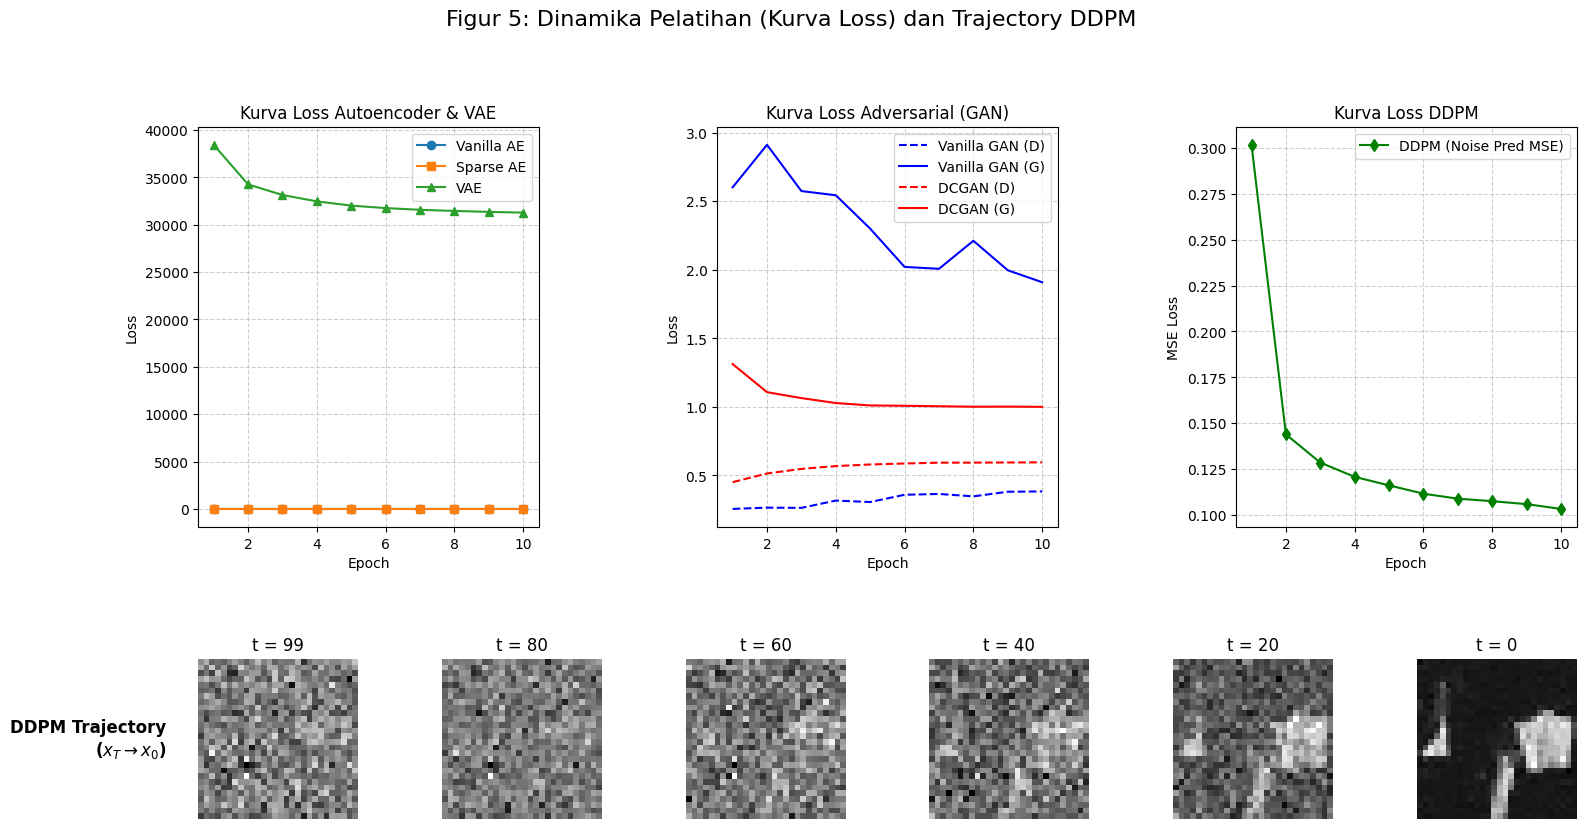

In [52]:
epochs = np.arange(1, 11)

unet.eval()
trajectory_imgs = []
steps_to_save = [99, 80, 60, 40, 20, 0]

with torch.no_grad():
    x_t = torch.randn(1, 1, 28, 28).to(device)

    for t_step in reversed(range(T)):
        t_tensor = torch.full((1,), t_step, device=device, dtype=torch.long)
        pred_noise = unet(x_t, t_tensor)

        beta_t = beta[t_step]
        alpha_t = alpha[t_step]
        a_bar_t = alpha_bar[t_step]

        noise = torch.randn_like(x_t) if t_step > 0 else torch.zeros_like(x_t)
        x_t = (1 / torch.sqrt(alpha_t)) * (x_t - ((1 - alpha_t) / torch.sqrt(1 - a_bar_t)) * pred_noise) + torch.sqrt(beta_t) * noise

        if t_step in steps_to_save:
            img = x_t.view(28, 28).cpu().numpy()
            img = (img - img.min()) / (img.max() - img.min() + 1e-8)
            trajectory_imgs.append(img)

fig = plt.figure(figsize=(16, 9))

ax1 = plt.subplot2grid((2, 3), (0, 0))
ax1.plot(epochs, history_loss_vanilla, label='Vanilla AE', marker='o')
ax1.plot(epochs, history_loss_sparse, label='Sparse AE', marker='s')
ax1.plot(epochs, history_loss_vae, label='VAE', marker='^')
ax1.set_title("Kurva Loss Autoencoder & VAE")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.legend()
ax1.grid(True, linestyle='--', alpha=0.6)

ax2 = plt.subplot2grid((2, 3), (0, 1))
ax2.plot(epochs, history_loss_gan_d, label='Vanilla GAN (D)', linestyle='--', color='blue')
ax2.plot(epochs, history_loss_gan_g, label='Vanilla GAN (G)', color='blue')
ax2.plot(epochs, history_loss_dcgan_d, label='DCGAN (D)', linestyle='--', color='red')
ax2.plot(epochs, history_loss_dcgan_g, label='DCGAN (G)', color='red')
ax2.set_title("Kurva Loss Adversarial (GAN)")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Loss")
ax2.legend()
ax2.grid(True, linestyle='--', alpha=0.6)

ax3 = plt.subplot2grid((2, 3), (0, 2))
ax3.plot(epochs, history_loss_ddpm, label='DDPM (Noise Pred MSE)', color='green', marker='d')
ax3.set_title("Kurva Loss DDPM")
ax3.set_xlabel("Epoch")
ax3.set_ylabel("MSE Loss")
ax3.legend()
ax3.grid(True, linestyle='--', alpha=0.6)

for idx, (img, t_val) in enumerate(zip(trajectory_imgs, steps_to_save)):
    ax = plt.subplot2grid((2, 6), (1, idx))
    ax.imshow(img, cmap='gray')
    ax.axis('off')
    ax.set_title(f"t = {t_val}")
    if idx == 0:
        ax.text(-0.2, 0.5, 'DDPM Trajectory\n($x_T \\rightarrow x_0$)', va='center', ha='right',
                transform=ax.transAxes, fontsize=12, fontweight='bold')

plt.suptitle("Figur 5: Dinamika Pelatihan (Kurva Loss) dan Trajectory DDPM", fontsize=16, y=1.05)
plt.tight_layout()
plt.savefig('figur_5.png', dpi=300, bbox_inches='tight')
plt.show()

# FID

In [53]:
def prepare_image(imgs_tensor):
  imgs_uint8=(imgs_tensor*255).to(torch.uint8)
  imgs_rgb=imgs_uint8.repeat(1,3,1,1)
  return imgs_rgb

def calculate_fid(model,dataloader,device,model_name,is_ddpm=False):
  fid=FrechetInceptionDistance(feature=64).to(device)

  model.eval()
  batch_count=0
  max_batches=10

  with torch.no_grad():
    for real_imgs,_ in dataloader:
      if batch_count>=max_batches:
        break

      real_imgs=real_imgs.to(device)
      batch_size=real_imgs.size(0)

      real_rgb=prepare_image(real_imgs)
      fid.update(real_rgb,real=True)

      if is_ddpm:
        x_t=torch.randn(batch_size,1,28,28).to(device)
        for t_step in reversed(range(T)):
          t_tensor=torch.full((batch_size,),t_step,device=device,dtype=torch.long)
          pred_noise=unet(x_t,t_tensor)

          beta_t=beta[t_step]
          alpha_t=alpha[t_step]
          a_bar_t=alpha_bar[t_step]
          noise=torch.randn_like(x_t) if t_step>0 else torch.zeros_like(x_t)
          x_t=(1/torch.sqrt(alpha_t))*(x_t-((1-alpha_t)/torch.sqrt(1-a_bar_t))*pred_noise)+torch.sqrt(beta_t)*noise

        fake_imgs=x_t
        fake_imgs=(fake_imgs-fake_imgs.min())/(fake_imgs.max()-fake_imgs.min()+1e-8)

      elif model_name=="VAE":
        z=torch.randn(batch_size,64).to(device)
        fake_imgs=model.decoder(z).view(-1,1,28,28)

      elif model_name=="DCGAN":
        z=torch.randn(batch_size,LATENT_DIM,1,1).to(device)
        fake_imgs=model(z)

      elif model_name=="Vanilla GAN":
        z=torch.randn(batch_size,LATENT_DIM).to(device)
        fake_imgs=generator(z).view(-1,1,28,28)

      fake_rgb=prepare_image(fake_imgs)
      fid.update(fake_rgb,real=False)

      batch_count+=1

  fid_score=fid.compute().item()
  print(f"FID Score [{model_name:<12}]: {fid_score:.2f}")
  return fid_score

In [54]:
fid_vae = calculate_fid(vae, dataloaders['test'], device, "VAE")
fid_gan = calculate_fid(generator, dataloaders['test'], device, "Vanilla GAN")
fid_dcgan = calculate_fid(generator_dc, dataloaders['test'], device, "DCGAN")
fid_ddpm = calculate_fid(unet, dataloaders['test'], device, "DDPM", is_ddpm=True)

Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:00<00:00, 271MB/s]


FID Score [VAE         ]: 0.51
FID Score [Vanilla GAN ]: 1.36
FID Score [DCGAN       ]: 0.01
FID Score [DDPM        ]: 2.52
